# Week-45

- take lastest version of paper (Oct 13):
    - update all figures with the last:
        - figure 2, 3, 4, 5
        - sup figure 2, 3, 8

        - sup fig 5 adjust the caption of the figure since it is wrong format the subexpont

    - add the methodology to the manuscript for the new embedding
        - update metrics values
        - add it at the end

    


- SEAL:
    - explain why it improves the seal

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Loading and validating the five result sets...
[PASS] Matched 290/290 food webs; 1,450 method-level rows and 7,250 plotting observations.

=== Input and protocol audit ===


,Method,Source,Food webs,Raw runs,Runs/web,Aggregation,Test negatives:positives,Target train ratio,Achieved ratio recorded,Threshold,Notes
0,WLNM original,result_wlnm_original_100x290_train10-90_thresh...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
1,WLNM directed-negative,result_wlnm_dir_neg_roleonly_trophicv2_100x290...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
2,WLNM directed + node ecology,result_wlnm_dir_neg_node_ecology_100x290_train...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
3,SEAL original,src/python/seal_original_gpu/data/result_seal_...,290,2900,10,Mean across repeats,1:1,90%,50.00–94.74% (median 90.23%),0.50,Balanced held-out positives/negatives; CUDA ca...
4,SEAL node,src/python/seal_directed/data/result_seal_dire...,290,2900,10,Mean across repeats,1:1,90%,90.00–94.74% (median 90.13%),0.50,Balanced held-out positives/negatives; role-po...



=== WLNM raw-run counts for the five common metrics ===


,Metric,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns,Method
0,ROC-AUC,290,100,100.0,100,WLNM original
1,PR-AUC,290,100,100.0,100,WLNM original
2,F1,290,100,100.0,100,WLNM original
3,Precision,290,100,100.0,100,WLNM original
4,Recall,290,100,100.0,100,WLNM original
5,ROC-AUC,290,100,100.0,100,WLNM directed-negative
6,PR-AUC,290,100,100.0,100,WLNM directed-negative
7,F1,290,100,100.0,100,WLNM directed-negative
8,Precision,290,100,100.0,100,WLNM directed-negative
9,Recall,290,100,100.0,100,WLNM directed-negative



=== Food-web-level descriptive medians ===


Method,WLNM original,WLNM directed-negative,WLNM directed + node ecology,SEAL original,SEAL node
Metric,,,,,
ROC-AUC,0.8306,0.9102,0.9847,0.8152,0.9148
PR-AUC,0.6032,0.5475,0.6179,0.8099,0.9153
F1,0.6591,0.7201,0.9369,0.7487,0.8396
Precision,0.7180,0.9507,0.9761,0.7174,0.8335
Recall,0.6372,0.6079,0.9238,0.8064,0.8556



[PASS] Generated 25 boxplots (5 methods × 5 metrics).


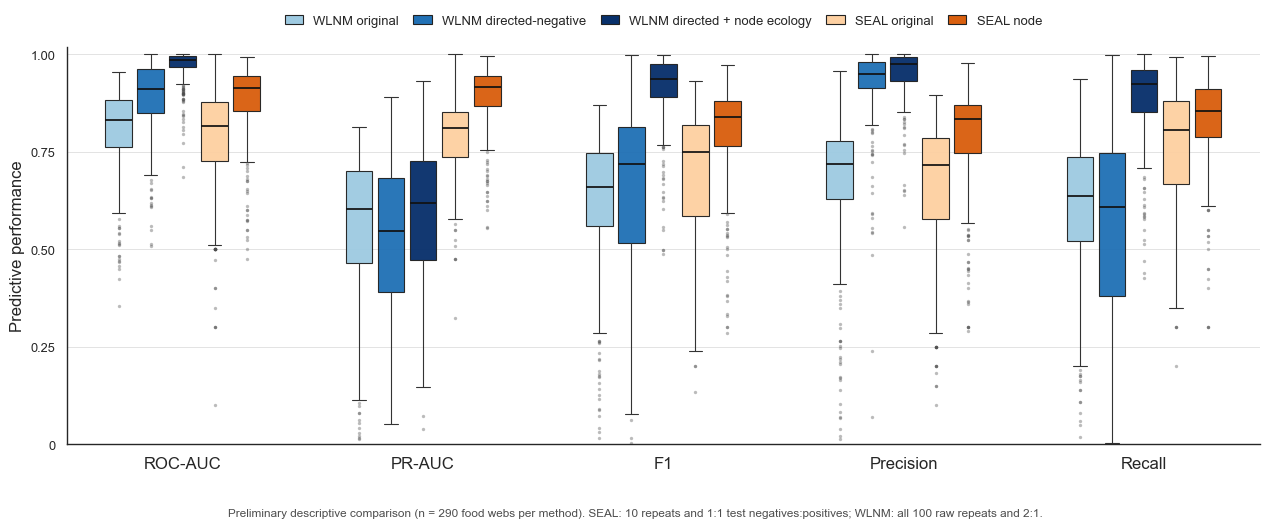

In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Patch




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained for compatibility with the existing
    plotting and summary code.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Configuration
# ============================================================

def find_repo_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / ".git").exists() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError(f"Repository root not found from {start}")


REPO_ROOT = find_repo_root(Path.cwd())
TRAIN_RATIO = 90
THRESHOLD = 0.50
N_WEBS = 290
WLNM_RUNS = 100
MIN_RETAINED = 25
RETENTION = "all_raw_runs_no_tukey_threshold0p50_v1"

WLNM_ROOTS = {
    "WLNM_original": REPO_ROOT / "src/matlab/data/result_wlnm_original_100x290_train10-90_thresh0p50_Apocrita_20260916_221905",
    "WLNM_dir_neg": REPO_ROOT / "src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848",
    "WLNM_dir_neg_node_ecology": REPO_ROOT / "src/matlab/data/result_wlnm_dir_neg_node_ecology_100x290_train10-90_Apocrita_20261109_193213",
}
SEAL_ORIGINAL_10X_ROOT = REPO_ROOT / "src/python/seal_original_gpu/data/result_seal_original_10x290_9736688d_20261019"
SEAL_DIRECTED_10X_ROOT = REPO_ROOT / "src/python/seal_directed/data/result_seal_directed_10x290_220d0a21_20261014"
SEAL_CONFIG = {
    "SEAL_original": {
        "results": SEAL_ORIGINAL_10X_ROOT / "prediction_scores_logs",
        "logs": SEAL_ORIGINAL_10X_ROOT / "runs",
        "log_pattern": "*/experiment_*_seed_*/terminal.log",
        "validation": SEAL_ORIGINAL_10X_ROOT / "summary/RUN_VALIDATION.json",
        "validation_expected": {
            "status": "VALIDATION_OK",
            "experiments": 10,
            "foodwebs": N_WEBS,
            "manifest_rows": N_WEBS * 10,
            "validated_runs": N_WEBS * 10,
            "distinct_numeric_seeds": 10,
            "nonfinite_predictive_metrics": 0,
            "core_logic_policy": "exact_historical_behavior_no_corrections",
        },
        "device_column": False,
        "pattern": "*_results_SEAL.csv",
        "version": "SEAL_undirected",
        "repeats": 10,
        "seeds": set(range(12345, 12355)),
        "fallbacks": 0,
    },
    "SEAL_directed": {
        "results": SEAL_DIRECTED_10X_ROOT / "prediction_scores_logs",
        "logs": SEAL_DIRECTED_10X_ROOT / "task_logs",
        "log_pattern": "**/*.log",
        "validation": SEAL_DIRECTED_10X_ROOT / "summary/RUN_VALIDATION.json",
        "validation_expected": {
            "status": "VALIDATION_OK",
            "experiments": 10,
            "foodwebs": N_WEBS,
            "manifest_rows": N_WEBS * 10,
            "validated_runs": N_WEBS * 10,
            "unique_seeds": N_WEBS * 10,
            "fallback_runs": 80,
        },
        "device_column": True,
        "pattern": "*_results_SEAL_directed.csv",
        "version": "SEAL_directed",
        "repeats": 10,
        "seeds": set(range(12345, 12345 + N_WEBS * 10)),
        "fallbacks": 80,
    },
}
METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
]
METRICS = [x for x, _ in METRIC_SPECS]
METRIC_LABELS = dict(METRIC_SPECS)
METHOD_ORDER = ["WLNM_original", "WLNM_dir_neg", "WLNM_dir_neg_node_ecology", "SEAL_original", "SEAL_directed"]
METHOD_LABELS = {
    "WLNM_original": "WLNM original",
    "WLNM_dir_neg": "WLNM directed-negative",
    "WLNM_dir_neg_node_ecology": "WLNM directed + node ecology",
    "SEAL_original": "SEAL original",
    "SEAL_directed": "SEAL node",
}
PALETTE = {
    "WLNM_original": "#9ECAE1",
    "WLNM_dir_neg": "#2171B5",
    "WLNM_dir_neg_node_ecology": "#08306B",
    "SEAL_original": "#FDD0A2",
    "SEAL_directed": "#D95F0E",
}


# ============================================================
# Loaders and validation
# ============================================================

def fw_key(value):
    text = Path(str(value)).stem.strip()
    text = re.sub(r"_tax_mass_results_SEAL(?:_directed)?$", "", text, flags=re.I)
    text = re.sub(r"_tax_mass_results_random_wlnm_(?:original|dir_neg(?:_node_ecology)?)$", "", text, flags=re.I)
    return " ".join(re.sub(r"[^a-z0-9]+", " ", text.casefold()).split())


def validate_values(frame, label):
    values = frame[METRICS].apply(pd.to_numeric, errors="coerce")
    if values.isna().any().any():
        raise ValueError(f"{label}: missing or non-numeric metric values")
    array = values.to_numpy(float)
    if not np.isfinite(array).all() or ((array < 0) | (array > 1)).any():
        raise ValueError(f"{label}: metric values must be finite and within [0, 1]")


def validate_keys(frame, source_col, label):
    collisions = (
        frame[["FW_KEY", source_col]].drop_duplicates()
        .groupby("FW_KEY")[source_col].nunique()
    )
    if (collisions > 1).any():
        raise ValueError(f"{label}: normalized food-web name collision")
    if frame["FW_KEY"].nunique() != N_WEBS:
        raise ValueError(f"{label}: expected {N_WEBS} food webs")


def validate_wlnm_raw(root):
    files = sorted((root / "prediction_scores_logs").glob("*.csv"))
    if len(files) != N_WEBS:
        raise ValueError(f"{root.name}: expected {N_WEBS} raw CSV files")
    ratios = []
    total_rows = 0
    usecols = ["TrainRatio", "TestTP", "TestFP", "TestFN", "TestTN"]
    for path in files:
        data = pd.read_csv(path, usecols=usecols)
        data = data[np.isclose(data["TrainRatio"], TRAIN_RATIO)]
        if len(data) != WLNM_RUNS:
            raise ValueError(f"{path.name}: expected {WLNM_RUNS} train-90 runs")
        positives = data["TestTP"] + data["TestFN"]
        negatives = data["TestFP"] + data["TestTN"]
        if (positives <= 0).any():
            raise ValueError(f"{path.name}: invalid test-positive count")
        ratios.extend((negatives / positives).to_numpy(float))
        total_rows += len(data)
    ratios = np.asarray(ratios)
    if not np.allclose(ratios, 2.0):
        raise ValueError(f"{root.name}: test negative:positive ratio is not 2:1")
    return total_rows


def load_wlnm(method):
    root = WLNM_ROOTS[method]
    data = load_raw_predictive_compat(
        root,
        method,
        METRIC_SPECS,
        WLNM_RUNS,
        WLNM_RUNS,
        train_ratios=[TRAIN_RATIO],
    )
    data["FW_KEY"] = data["Foodweb"].map(fw_key)
    validate_keys(data, "Foodweb", method)
    if data.duplicated(["FW_KEY", "Metric"]).any():
        raise ValueError(f"{method}: duplicate food-web/metric rows")
    wide = (
        data.pivot(
            index="FW_KEY",
            columns="Metric",
            values="MeanAfterTukey",
        )
        .rename_axis(None, axis=1)
        .reset_index()
    )
    validate_values(wide, method)
    wide["Method"] = method
    raw_rows = validate_wlnm_raw(root)
    retention = data.groupby("Metric", as_index=False).agg(
        FoodWebs=("FW_KEY", "nunique"),
        MinimumRetainedRuns=("RetainedRunsAfterTukey", "min"),
        MedianRetainedRuns=("RetainedRunsAfterTukey", "median"),
        MaximumRetainedRuns=("RetainedRunsAfterTukey", "max"),
    )
    retention["Method"] = METHOD_LABELS[method]
    retention["Metric"] = retention["Metric"].map(METRIC_LABELS)
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": root.name,
        "Food webs": N_WEBS,
        "Raw runs": raw_rows,
        "Runs/web": "100",
        "Aggregation": "Mean across all raw runs; no Tukey filtering",
        "Test negatives:positives": "2:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": "90% label",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": "All 100 raw runs included",
    }
    return wide, audit, retention

def load_seal(method, config):
    validation = None
    if validation_path := config.get("validation"):
        validation = json.loads(validation_path.read_text())
        expected_validation = config["validation_expected"]
        observed_validation = {
            key: validation.get(key) for key in expected_validation
        }
        if observed_validation != expected_validation:
            raise ValueError(
                f"{method}: unexpected campaign validation summary: "
                f"{observed_validation}"
            )
    files = sorted(config["results"].glob(config["pattern"]))
    if len(files) != N_WEBS:
        raise ValueError(f"{method}: expected {N_WEBS} result CSVs, found {len(files)}")
    frames = []
    required = set(METRICS) | {"Version", "TrainRatio", "ExperimentID", "Seed", "Threshold"}
    if config.get("device_column", False):
        required.add("Device")
    for path in files:
        data = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        if missing := required.difference(data.columns):
            raise ValueError(f"{path.name}: missing {sorted(missing)}")
        source_foodweb = re.sub(
            r"_tax_mass_results_SEAL(?:_directed)?\.csv$",
            "",
            path.name,
            flags=re.I,
        )
        data = data.assign(
            SourceFoodweb=source_foodweb,
            FW_KEY=fw_key(source_foodweb),
        )
        frames.append(data)
    raw = pd.concat(frames, ignore_index=True)
    validate_keys(raw, "SourceFoodweb", method)
    if config.get("device_column", False):
        if "Device" not in raw or set(raw["Device"].unique()) != {"cuda:0"}:
            raise ValueError(f"{method}: expected every validated run to use cuda:0")
    if set(raw["Version"].unique()) != {config["version"]}:
        raise ValueError(f"{method}: unexpected Version")
    if not np.allclose(raw["Threshold"], THRESHOLD):
        raise ValueError(f"{method}: unexpected threshold")
    if set(raw["Seed"].astype(int)) != config["seeds"] or set(raw["ExperimentID"].astype(int)) != set(range(1, config["repeats"] + 1)):
        raise ValueError(f"{method}: unexpected seeds or ExperimentID values")
    if set(raw.groupby("FW_KEY").size()) != {config["repeats"]}:
        raise ValueError(f"{method}: unexpected repeats per food web")
    if raw.duplicated(["FW_KEY", "ExperimentID"]).any():
        raise ValueError(f"{method}: duplicate food-web/experiment rows")
    validate_values(raw, method)

    log_files = sorted(config["logs"].glob(config["log_pattern"]))
    if len(log_files) != len(raw):
        raise ValueError(f"{method}: expected {len(raw)} terminal logs, found {len(log_files)}")
    fallback_text = "role-constrained negative pool too small; falling back to all directed unknown links"
    fallbacks = sum(fallback_text in path.read_text(errors="replace") for path in log_files)
    if fallbacks != config["fallbacks"]:
        raise ValueError(f"{method}: expected {config['fallbacks']} fallbacks, found {fallbacks}")

    wide = raw.groupby("FW_KEY", as_index=False)[METRICS].mean()
    validate_values(wide, f"{method} means")
    wide["Method"] = method
    ratio_min, ratio_median, ratio_max = raw.TrainRatio.min(), raw.TrainRatio.median(), raw.TrainRatio.max()
    note = "Balanced held-out positives/negatives"
    if method == "SEAL_directed":
        note += f"; role-pool fallback in {fallbacks}/{len(raw)} runs"
    if validation is not None:
        note += "; CUDA campaign VALIDATION_OK"
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": str(config["results"].relative_to(REPO_ROOT)),
        "Food webs": N_WEBS,
        "Raw runs": len(raw),
        "Runs/web": str(config["repeats"]),
        "Aggregation": "Mean across repeats",
        "Test negatives:positives": "1:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": f"{ratio_min:.2f}–{ratio_max:.2f}% (median {ratio_median:.2f}%)",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": note,
    }
    return wide, audit


# ============================================================
# Build the matched comparison table
# ============================================================

print(f"[INFO] Repository: {REPO_ROOT}")
print("[INFO] Loading and validating the five result sets...")

wlnm_original, audit_wo, retention_wo = load_wlnm("WLNM_original")
wlnm_dir_neg, audit_wd, retention_wd = load_wlnm("WLNM_dir_neg")
wlnm_node_ecology, audit_wne, retention_wne = load_wlnm("WLNM_dir_neg_node_ecology")
seal_original, audit_so = load_seal("SEAL_original", SEAL_CONFIG["SEAL_original"])
seal_directed, audit_sd = load_seal("SEAL_directed", SEAL_CONFIG["SEAL_directed"])
frames = {
    "WLNM_original": wlnm_original,
    "WLNM_dir_neg": wlnm_dir_neg,
    "WLNM_dir_neg_node_ecology": wlnm_node_ecology,
    "SEAL_original": seal_original,
    "SEAL_directed": seal_directed,
}
key_sets = {method: set(frame.FW_KEY) for method, frame in frames.items()}
common = set.intersection(*key_sets.values())
union = set.union(*key_sets.values())
if len(common) != N_WEBS or len(union) != N_WEBS:
    details = {method: {"missing": sorted(union - keys)[:10], "unpaired": sorted(keys - common)[:10]} for method, keys in key_sets.items()}
    raise ValueError(f"Food-web matching failed: {details}")

comparison_wide = pd.concat([frames[m] for m in METHOD_ORDER], ignore_index=True)[["FW_KEY", "Method", *METRICS]]
if comparison_wide.shape != (1450, 7) or comparison_wide.duplicated(["FW_KEY", "Method"]).any():
    raise ValueError(f"Invalid wide table: shape={comparison_wide.shape}")
validate_values(comparison_wide, "combined comparison")
comparison_long = comparison_wide.melt(
    id_vars=["FW_KEY", "Method"], value_vars=METRICS,
    var_name="Metric", value_name="Value",
)
comparison_long["MethodLabel"] = comparison_long.Method.map(METHOD_LABELS)
comparison_long["MetricLabel"] = comparison_long.Metric.map(METRIC_LABELS)
if len(comparison_long) != 7250 or comparison_long.Value.isna().any():
    raise ValueError(f"Invalid long table: rows={len(comparison_long)}")
print("[PASS] Matched 290/290 food webs; 1,450 method-level rows and 7,250 plotting observations.")


# ============================================================
# Audit and descriptive summaries
# ============================================================

audit_table = pd.DataFrame([audit_wo, audit_wd, audit_wne, audit_so, audit_sd])
print("\n=== Input and protocol audit ===")
display(audit_table)

retention_table = pd.concat([retention_wo, retention_wd, retention_wne], ignore_index=True)
metric_order = [label for _, label in METRIC_SPECS]
retention_table["Metric"] = pd.Categorical(retention_table.Metric, metric_order, ordered=True)
retention_table["Method"] = pd.Categorical(
    retention_table.Method,
    [METHOD_LABELS[m] for m in METHOD_ORDER[:3]],
    ordered=True,
)
retention_table = retention_table.sort_values(["Method", "Metric"]).reset_index(drop=True)
print("\n=== WLNM raw-run counts for the five common metrics ===")
display(retention_table)

median_table = (
    comparison_long.groupby(["Metric", "Method"], observed=True).Value.median()
    .unstack("Method").reindex(index=METRICS, columns=METHOD_ORDER)
    .rename(index=METRIC_LABELS, columns=METHOD_LABELS).round(4)
)
print("\n=== Food-web-level descriptive medians ===")
display(median_table)

# print("\n[CAUTION] Preliminary descriptive comparison only. SEAL uses 10 repeats and a 1:1 held-out negative:positive ratio; WLNM uses all 100 raw repeats and a 2:1 ratio. PR-AUC, Precision and F1 are especially sensitive to this prevalence difference.")
# print("[CAUTION] 'SEAL node' is the complete current configuration (directionality, node attributes and role-aware negative sampling), not a direction-only ablation.")


# ============================================================
# Grouped boxplots (one value per food web and method)
# ============================================================

sns.set_theme(context="paper", style="white", font_scale=1.05)
fig, ax = plt.subplots(figsize=(12.8, 5.8))
centers = np.arange(len(METRICS), dtype=float) * 1.35 + 1.0
offsets = {"WLNM_original": -0.36, "WLNM_dir_neg": -0.18, "WLNM_dir_neg_node_ecology": 0.00, "SEAL_original": 0.18, "SEAL_directed": 0.36}
box_count = 0
for method in METHOD_ORDER:
    datasets, positions = [], []
    for i, metric in enumerate(METRICS):
        values = comparison_long.loc[
            comparison_long.Method.eq(method) & comparison_long.Metric.eq(metric), "Value"
        ].to_numpy(float)
        if len(values) != N_WEBS:
            raise ValueError(f"{method}/{metric}: expected {N_WEBS} values")
        datasets.append(values)
        positions.append(centers[i] + offsets[method])
    artists = ax.boxplot(
        datasets, positions=positions, widths=0.15, patch_artist=True,
        manage_ticks=False, showfliers=True, whis=1.5,
        boxprops={"facecolor": PALETTE[method], "edgecolor": "#222222", "linewidth": 0.8, "alpha": 0.96},
        medianprops={"color": "#111111", "linewidth": 1.25},
        whiskerprops={"color": "#333333", "linewidth": 0.8},
        capprops={"color": "#333333", "linewidth": 0.8},
        flierprops={"marker": "o", "markersize": 2.4, "markerfacecolor": "#4D4D4D", "markeredgecolor": "none", "alpha": 0.38},
    )
    box_count += len(artists["boxes"])
if box_count != 25:
    raise RuntimeError(f"Expected 25 box artists, created {box_count}")

handles = [Patch(facecolor=PALETTE[m], edgecolor="#222222", linewidth=0.8, label=METHOD_LABELS[m]) for m in METHOD_ORDER]
ax.set_xlim(centers[0] - 0.65, centers[-1] + 0.65)
ax.set_ylim(0, 1.02)
ax.set_xticks(centers, [METRIC_LABELS[m] for m in METRICS], fontsize=12)
ax.set_yticks([0, 0.25, 0.50, 0.75, 1.00], ["0", "0.25", "0.50", "0.75", "1.00"])
ax.set_ylabel("Predictive performance", fontsize=12)
ax.grid(axis="y", color="#D9D9D9", linewidth=0.7, alpha=0.75)
ax.set_axisbelow(True)
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=5, frameon=False, fontsize=9.4, columnspacing=1.1, handlelength=1.4)
sns.despine(ax=ax)
fig.text(
    0.5, 0.015,
    "Preliminary descriptive comparison (n = 290 food webs per method). SEAL: 10 repeats and 1:1 test negatives:positives; WLNM: all 100 raw repeats and 2:1.",
    ha="center", va="bottom", fontsize=8.5, color="#4D4D4D",
)
fig.tight_layout(rect=(0, 0.07, 1, 0.92))
print(f"\n[PASS] Generated {box_count} boxplots (5 methods × 5 metrics).")
plt.show()

[INFO] Repository: /Users/acw792/Developer/qmul-phd-framework
[INFO] Loading and validating the seven result sets...
[PASS] Matched 290/290 food webs; 2,030 method-level rows and 10,150 plotting observations.

=== Input and protocol audit ===


,Method,Source,Food webs,Raw runs,Runs/web,Aggregation,Test negatives:positives,Target train ratio,Achieved ratio recorded,Threshold,Notes
0,WLNM original,result_wlnm_original_100x290_train10-90_thresh...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
1,WLNM directed-negative,result_wlnm_dir_neg_roleonly_trophicv2_100x290...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
2,WLNM directed + node ecology,result_wlnm_dir_neg_node_ecology_100x290_train...,290,29000,100,Mean across all raw runs; no Tukey filtering,2:1,90%,90% label,0.50,All 100 raw runs included
3,SEAL original,src/python/seal_original_gpu/data/result_seal_...,290,2900,10,Mean across repeats,1:1,90%,50.00–94.74% (median 90.23%),0.50,Balanced held-out positives/negatives; CUDA ca...
4,SEAL node,src/python/seal_directed/data/result_seal_dire...,290,2900,10,Mean across repeats,1:1,90%,90.00–94.74% (median 90.13%),0.50,Balanced held-out positives/negatives; role-po...
5,SEAL node+edge Gate,src/python/seal_directed_weighted/data/result_...,290,2900,10,Mean across all 10 raw runs,1:1,90%,90.00–94.74% (median 90.13%),0.50,CUDA; 44 node attributes + 17 contextual edge ...
6,SEAL node+edge ECC,src/python/seal_directed_weighted/data/result_...,290,2900,10,Mean across all 10 raw runs,1:1,90%,90.00–94.74% (median 90.13%),0.50,CUDA; 44 node attributes + 17 contextual edge ...



=== WLNM raw-run counts for the five common metrics ===


,Metric,FoodWebs,MinimumRetainedRuns,MedianRetainedRuns,MaximumRetainedRuns,Method
0,ROC-AUC,290,100,100.0,100,WLNM original
1,PR-AUC,290,100,100.0,100,WLNM original
2,F1,290,100,100.0,100,WLNM original
3,Precision,290,100,100.0,100,WLNM original
4,Recall,290,100,100.0,100,WLNM original
5,ROC-AUC,290,100,100.0,100,WLNM directed-negative
6,PR-AUC,290,100,100.0,100,WLNM directed-negative
7,F1,290,100,100.0,100,WLNM directed-negative
8,Precision,290,100,100.0,100,WLNM directed-negative
9,Recall,290,100,100.0,100,WLNM directed-negative



=== Food-web-level descriptive medians ===


Method,WLNM original,WLNM directed-negative,WLNM directed + node ecology,SEAL original,SEAL node,SEAL node+edge Gate,SEAL node+edge ECC
Metric,,,,,,,
ROC-AUC,0.8306,0.9102,0.9847,0.8152,0.9148,0.9213,0.9506
PR-AUC,0.6032,0.5475,0.6179,0.8099,0.9153,0.9272,0.9555
F1,0.6591,0.7201,0.9369,0.7487,0.8396,0.8491,0.8833
Precision,0.7180,0.9507,0.9761,0.7174,0.8335,0.8514,0.9027
Recall,0.6372,0.6079,0.9238,0.8064,0.8556,0.8516,0.8800



[PASS] Generated 35 boxplots (7 methods × 5 metrics).


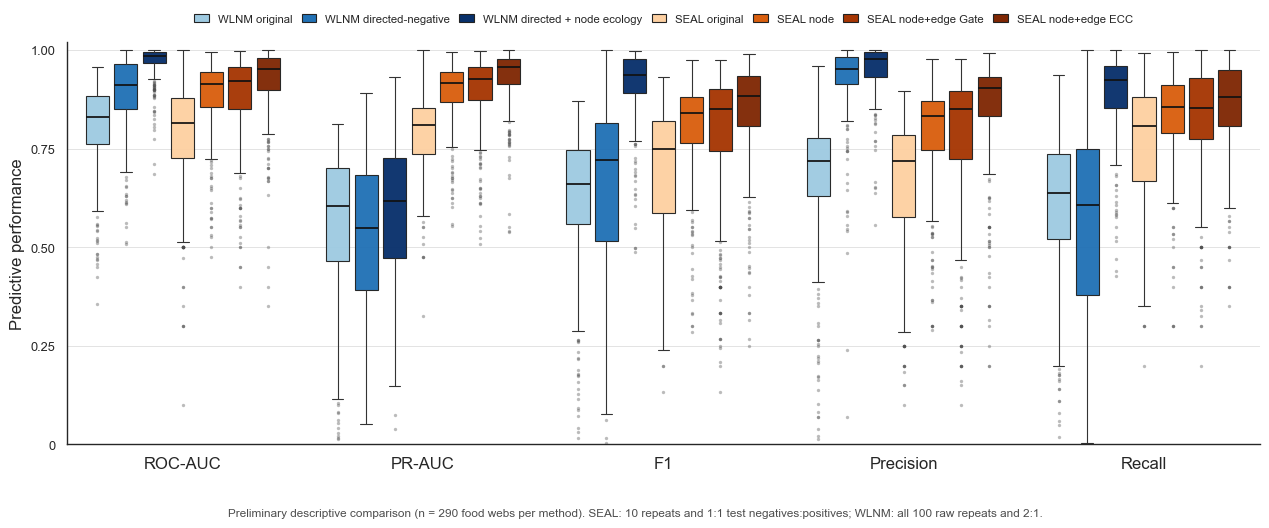

In [2]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Patch




# ============================================================
# Raw predictive inputs (no Tukey filtering)
# ============================================================

import re


def _raw_foodweb_name(path):
    return re.sub(
        r"_tax_mass_results_random_wlnm_.*$",
        "",
        path.stem,
        flags=re.I,
    )


def load_raw_predictive_compat(
    result_root,
    expected_version,
    metric_specs,
    expected_runs,
    minimum_retained_runs,
    *,
    train_ratios=None,
    cvk_values=None,
    k_target=10,
    threshold=0.50,
    kfold=False,
    scenario=None,
):
    """Return raw web-level means in the legacy plotting schema.

    The legacy column names are retained for compatibility with the existing
    plotting and summary code.
    MeanAfterTukey below is a compatibility alias for the arithmetic mean of
    every complete raw run unit; no Tukey fences or outlier exclusions occur.
    """
    metrics = [metric for metric, _ in metric_specs]
    labels = dict(metric_specs)
    files = sorted((result_root / "prediction_scores_logs").glob("*.csv"))
    if not files:
        raise FileNotFoundError(result_root / "prediction_scores_logs")

    required = {
        "Version",
        "TrainRatio",
        "ExperimentID",
        "Seed",
        "Threshold",
        "K",
        "CvK",
        "FoldID",
        "EmpiricalConnectance",
        *metrics,
    }
    frames = []
    for path in files:
        frame = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        missing = required.difference(frame.columns)
        if missing:
            raise ValueError(
                f"{path.name}: missing raw columns {sorted(missing)}"
            )
        frame["Foodweb"] = _raw_foodweb_name(path)
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True)
    for column in required.difference({"Version"}):
        raw[column] = pd.to_numeric(raw[column], errors="coerce")
    raw["TrainRatio"] = np.where(
        raw["TrainRatio"].abs().le(1.0),
        raw["TrainRatio"] * 100.0,
        raw["TrainRatio"],
    )
    raw = raw.loc[
        raw["Version"].eq(expected_version)
        & np.isclose(raw["Threshold"], threshold, atol=1e-9)
        & np.isclose(raw["K"], k_target, atol=1e-9)
    ].copy()
    if train_ratios is not None:
        requested = np.asarray(list(train_ratios), dtype=float)
        raw = raw.loc[
            raw["TrainRatio"].map(
                lambda value: np.isclose(
                    value,
                    requested,
                    atol=1e-8,
                ).any()
            )
        ].copy()
    if cvk_values is not None:
        raw = raw.loc[raw["CvK"].isin(cvk_values)].copy()
    if raw.empty:
        raise ValueError(f"No raw observations selected from {result_root}")

    metric_values = raw[metrics].to_numpy(float)
    if not np.isfinite(metric_values).all():
        raise ValueError(f"Non-finite raw predictive values in {result_root}")
    probability_metrics = [
        metric for metric in metrics if metric not in {"TestMCC", "TestTSS"}
    ]
    signed_metrics = [
        metric for metric in metrics if metric in {"TestMCC", "TestTSS"}
    ]
    if probability_metrics:
        values = raw[probability_metrics].to_numpy(float)
        if ((values < 0) | (values > 1)).any():
            raise ValueError("Raw probability metrics must be within [0, 1]")
    if signed_metrics:
        values = raw[signed_metrics].to_numpy(float)
        if ((values < -1) | (values > 1)).any():
            raise ValueError("Raw MCC/TSS values must be within [-1, 1]")

    group_columns = [
        "Foodweb",
        "Version",
        "TrainRatio",
        "Threshold",
        "K",
        "CvK",
    ]
    if kfold:
        experiment_columns = [*group_columns, "ExperimentID"]
        fold_check = (
            raw.groupby(experiment_columns, dropna=False)
            .agg(
                FoldRows=("FoldID", "size"),
                UniqueFolds=("FoldID", "nunique"),
            )
            .reset_index()
        )
        incomplete = fold_check.loc[
            ~fold_check["FoldRows"].eq(fold_check["CvK"])
            | ~fold_check["UniqueFolds"].eq(fold_check["CvK"])
        ]
        if not incomplete.empty:
            raise ValueError(
                "Incomplete repeated-CV experiments found:\n"
                + incomplete.head(10).to_string(index=False)
            )
        run_units = (
            raw.groupby(
                experiment_columns,
                dropna=False,
                as_index=False,
            )
            .agg(
                **{
                    metric: (metric, "mean")
                    for metric in metrics
                },
                EmpiricalConnectance=(
                    "EmpiricalConnectance",
                    "first",
                ),
            )
        )
    else:
        experiment_columns = [*group_columns, "ExperimentID"]
        if raw.duplicated(experiment_columns).any():
            raise ValueError(f"Duplicate raw ExperimentID rows in {result_root}")
        run_units = raw

    counts = run_units.groupby(group_columns, dropna=False).size()
    if not counts.eq(expected_runs).all():
        raise ValueError(
            f"{result_root.name}: expected {expected_runs} complete raw "
            "run units per group; observed "
            f"{counts.value_counts().to_dict()}"
        )

    wide = (
        run_units.groupby(
            group_columns,
            dropna=False,
            as_index=False,
        )
        .agg(
            **{
                metric: (metric, "mean")
                for metric in metrics
            },
            EmpiricalConnectance=(
                "EmpiricalConnectance",
                "first",
            ),
            RawRunUnits=("ExperimentID", "size"),
        )
    )
    long = wide.melt(
        id_vars=[
            *group_columns,
            "EmpiricalConnectance",
            "RawRunUnits",
        ],
        value_vars=metrics,
        var_name="Metric",
        value_name="MeanAfterTukey",
    )
    long["Scenario"] = scenario or result_root.name
    long["MetricLabel"] = long["Metric"].map(labels)
    long["MetricFamily"] = "predictive"
    long["SourceColumn"] = long["Metric"]
    long["ReferenceColumn"] = ""
    long["MeanBeforeTukey"] = long["MeanAfterTukey"]
    long["TotalRunUnits"] = long["RawRunUnits"]
    long["ValidRunsBeforeTukey"] = long["RawRunUnits"]
    long["InvalidRunsBeforeTukey"] = 0
    long["OutlierRunsExcluded"] = 0
    long["RetainedRunsAfterTukey"] = long["RawRunUnits"]
    long["ExpectedRuns"] = expected_runs
    long["MinimumRetainedRuns"] = minimum_retained_runs
    long["MeetsMinimumRetainedRuns"] = 1
    long["ReferenceValue"] = long["EmpiricalConnectance"]
    return long

# ============================================================
# Configuration
# ============================================================

def find_repo_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / ".git").exists() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError(f"Repository root not found from {start}")


REPO_ROOT = find_repo_root(Path.cwd())
TRAIN_RATIO = 90
THRESHOLD = 0.50
N_WEBS = 290
WLNM_RUNS = 100
MIN_RETAINED = 25
RETENTION = "all_raw_runs_no_tukey_threshold0p50_v1"

WLNM_ROOTS = {
    "WLNM_original": REPO_ROOT / "src/matlab/data/result_wlnm_original_100x290_train10-90_thresh0p50_Apocrita_20260916_221905",
    "WLNM_dir_neg": REPO_ROOT / "src/matlab/data/result_wlnm_dir_neg_roleonly_trophicv2_100x290_train10-90_Apocrita_20260910_011848",
    "WLNM_dir_neg_node_ecology": REPO_ROOT / "src/matlab/data/result_wlnm_dir_neg_node_ecology_100x290_train10-90_Apocrita_20261109_193213",
}
SEAL_ORIGINAL_10X_ROOT = REPO_ROOT / "src/python/seal_original_gpu/data/result_seal_original_10x290_9736688d_20261019"
SEAL_DIRECTED_10X_ROOT = REPO_ROOT / "src/python/seal_directed/data/result_seal_directed_10x290_220d0a21_20261014"
SEAL_WEIGHTED_10X_ROOT = REPO_ROOT / "src/python/seal_directed_weighted/data/result_seal_directed_nodeedgeattr_10x290x4_Apocrita_fb60fd147be3_20261024"
SEAL_CONFIG = {
    "SEAL_original": {
        "results": SEAL_ORIGINAL_10X_ROOT / "prediction_scores_logs",
        "logs": SEAL_ORIGINAL_10X_ROOT / "runs",
        "log_pattern": "*/experiment_*_seed_*/terminal.log",
        "validation": SEAL_ORIGINAL_10X_ROOT / "summary/RUN_VALIDATION.json",
        "validation_expected": {
            "status": "VALIDATION_OK",
            "experiments": 10,
            "foodwebs": N_WEBS,
            "manifest_rows": N_WEBS * 10,
            "validated_runs": N_WEBS * 10,
            "distinct_numeric_seeds": 10,
            "nonfinite_predictive_metrics": 0,
            "core_logic_policy": "exact_historical_behavior_no_corrections",
        },
        "device_column": False,
        "pattern": "*_results_SEAL.csv",
        "version": "SEAL_undirected",
        "repeats": 10,
        "seeds": set(range(12345, 12355)),
        "fallbacks": 0,
    },
    "SEAL_directed": {
        "results": SEAL_DIRECTED_10X_ROOT / "prediction_scores_logs",
        "logs": SEAL_DIRECTED_10X_ROOT / "task_logs",
        "log_pattern": "**/*.log",
        "validation": SEAL_DIRECTED_10X_ROOT / "summary/RUN_VALIDATION.json",
        "validation_expected": {
            "status": "VALIDATION_OK",
            "experiments": 10,
            "foodwebs": N_WEBS,
            "manifest_rows": N_WEBS * 10,
            "validated_runs": N_WEBS * 10,
            "unique_seeds": N_WEBS * 10,
            "fallback_runs": 80,
        },
        "device_column": True,
        "pattern": "*_results_SEAL_directed.csv",
        "version": "SEAL_directed",
        "repeats": 10,
        "seeds": set(range(12345, 12345 + N_WEBS * 10)),
        "fallbacks": 80,
    },
}
METRIC_SPECS = [
    ("ROC_AUC", "ROC-AUC"),
    ("PR_AUC", "PR-AUC"),
    ("F1Score", "F1"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
]
METRICS = [x for x, _ in METRIC_SPECS]
METRIC_LABELS = dict(METRIC_SPECS)
METHOD_ORDER = ["WLNM_original", "WLNM_dir_neg", "WLNM_dir_neg_node_ecology", "SEAL_original", "SEAL_directed", "SEAL_directed_scalar_gate", "SEAL_directed_ecc"]
METHOD_LABELS = {
    "WLNM_original": "WLNM original",
    "WLNM_dir_neg": "WLNM directed-negative",
    "WLNM_dir_neg_node_ecology": "WLNM directed + node ecology",
    "SEAL_original": "SEAL original",
    "SEAL_directed": "SEAL node",
    "SEAL_directed_scalar_gate": "SEAL node+edge Gate",
    "SEAL_directed_ecc": "SEAL node+edge ECC",
}
PALETTE = {
    "WLNM_original": "#9ECAE1",
    "WLNM_dir_neg": "#2171B5",
    "WLNM_dir_neg_node_ecology": "#08306B",
    "SEAL_original": "#FDD0A2",
    "SEAL_directed": "#D95F0E",
    "SEAL_directed_scalar_gate": "#A63603",
    "SEAL_directed_ecc": "#7F2704",
}


# ============================================================
# Loaders and validation
# ============================================================

def fw_key(value):
    text = Path(str(value)).stem.strip()
    text = re.sub(r"_tax_mass_results_SEAL(?:_directed)?$", "", text, flags=re.I)
    text = re.sub(r"_tax_mass_results_random_wlnm_(?:original|dir_neg(?:_node_ecology)?)$", "", text, flags=re.I)
    return " ".join(re.sub(r"[^a-z0-9]+", " ", text.casefold()).split())


def validate_values(frame, label):
    values = frame[METRICS].apply(pd.to_numeric, errors="coerce")
    if values.isna().any().any():
        raise ValueError(f"{label}: missing or non-numeric metric values")
    array = values.to_numpy(float)
    if not np.isfinite(array).all() or ((array < 0) | (array > 1)).any():
        raise ValueError(f"{label}: metric values must be finite and within [0, 1]")


def validate_keys(frame, source_col, label):
    collisions = (
        frame[["FW_KEY", source_col]].drop_duplicates()
        .groupby("FW_KEY")[source_col].nunique()
    )
    if (collisions > 1).any():
        raise ValueError(f"{label}: normalized food-web name collision")
    if frame["FW_KEY"].nunique() != N_WEBS:
        raise ValueError(f"{label}: expected {N_WEBS} food webs")


def validate_wlnm_raw(root):
    files = sorted((root / "prediction_scores_logs").glob("*.csv"))
    if len(files) != N_WEBS:
        raise ValueError(f"{root.name}: expected {N_WEBS} raw CSV files")
    ratios = []
    total_rows = 0
    usecols = ["TrainRatio", "TestTP", "TestFP", "TestFN", "TestTN"]
    for path in files:
        data = pd.read_csv(path, usecols=usecols)
        data = data[np.isclose(data["TrainRatio"], TRAIN_RATIO)]
        if len(data) != WLNM_RUNS:
            raise ValueError(f"{path.name}: expected {WLNM_RUNS} train-90 runs")
        positives = data["TestTP"] + data["TestFN"]
        negatives = data["TestFP"] + data["TestTN"]
        if (positives <= 0).any():
            raise ValueError(f"{path.name}: invalid test-positive count")
        ratios.extend((negatives / positives).to_numpy(float))
        total_rows += len(data)
    ratios = np.asarray(ratios)
    if not np.allclose(ratios, 2.0):
        raise ValueError(f"{root.name}: test negative:positive ratio is not 2:1")
    return total_rows


def load_wlnm(method):
    root = WLNM_ROOTS[method]
    data = load_raw_predictive_compat(
        root,
        method,
        METRIC_SPECS,
        WLNM_RUNS,
        WLNM_RUNS,
        train_ratios=[TRAIN_RATIO],
    )
    data["FW_KEY"] = data["Foodweb"].map(fw_key)
    validate_keys(data, "Foodweb", method)
    if data.duplicated(["FW_KEY", "Metric"]).any():
        raise ValueError(f"{method}: duplicate food-web/metric rows")
    wide = (
        data.pivot(
            index="FW_KEY",
            columns="Metric",
            values="MeanAfterTukey",
        )
        .rename_axis(None, axis=1)
        .reset_index()
    )
    validate_values(wide, method)
    wide["Method"] = method
    raw_rows = validate_wlnm_raw(root)
    retention = data.groupby("Metric", as_index=False).agg(
        FoodWebs=("FW_KEY", "nunique"),
        MinimumRetainedRuns=("RetainedRunsAfterTukey", "min"),
        MedianRetainedRuns=("RetainedRunsAfterTukey", "median"),
        MaximumRetainedRuns=("RetainedRunsAfterTukey", "max"),
    )
    retention["Method"] = METHOD_LABELS[method]
    retention["Metric"] = retention["Metric"].map(METRIC_LABELS)
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": root.name,
        "Food webs": N_WEBS,
        "Raw runs": raw_rows,
        "Runs/web": "100",
        "Aggregation": "Mean across all raw runs; no Tukey filtering",
        "Test negatives:positives": "2:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": "90% label",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": "All 100 raw runs included",
    }
    return wide, audit, retention

def load_seal(method, config):
    validation = None
    if validation_path := config.get("validation"):
        validation = json.loads(validation_path.read_text())
        expected_validation = config["validation_expected"]
        observed_validation = {
            key: validation.get(key) for key in expected_validation
        }
        if observed_validation != expected_validation:
            raise ValueError(
                f"{method}: unexpected campaign validation summary: "
                f"{observed_validation}"
            )
    files = sorted(config["results"].glob(config["pattern"]))
    if len(files) != N_WEBS:
        raise ValueError(f"{method}: expected {N_WEBS} result CSVs, found {len(files)}")
    frames = []
    required = set(METRICS) | {"Version", "TrainRatio", "ExperimentID", "Seed", "Threshold"}
    if config.get("device_column", False):
        required.add("Device")
    for path in files:
        data = pd.read_csv(
            path,
            usecols=lambda column: column in required,
        )
        if missing := required.difference(data.columns):
            raise ValueError(f"{path.name}: missing {sorted(missing)}")
        source_foodweb = re.sub(
            r"_tax_mass_results_SEAL(?:_directed)?\.csv$",
            "",
            path.name,
            flags=re.I,
        )
        data = data.assign(
            SourceFoodweb=source_foodweb,
            FW_KEY=fw_key(source_foodweb),
        )
        frames.append(data)
    raw = pd.concat(frames, ignore_index=True)
    validate_keys(raw, "SourceFoodweb", method)
    if config.get("device_column", False):
        if "Device" not in raw or set(raw["Device"].unique()) != {"cuda:0"}:
            raise ValueError(f"{method}: expected every validated run to use cuda:0")
    if set(raw["Version"].unique()) != {config["version"]}:
        raise ValueError(f"{method}: unexpected Version")
    if not np.allclose(raw["Threshold"], THRESHOLD):
        raise ValueError(f"{method}: unexpected threshold")
    if set(raw["Seed"].astype(int)) != config["seeds"] or set(raw["ExperimentID"].astype(int)) != set(range(1, config["repeats"] + 1)):
        raise ValueError(f"{method}: unexpected seeds or ExperimentID values")
    if set(raw.groupby("FW_KEY").size()) != {config["repeats"]}:
        raise ValueError(f"{method}: unexpected repeats per food web")
    if raw.duplicated(["FW_KEY", "ExperimentID"]).any():
        raise ValueError(f"{method}: duplicate food-web/experiment rows")
    validate_values(raw, method)

    log_files = sorted(config["logs"].glob(config["log_pattern"]))
    if len(log_files) != len(raw):
        raise ValueError(f"{method}: expected {len(raw)} terminal logs, found {len(log_files)}")
    fallback_text = "role-constrained negative pool too small; falling back to all directed unknown links"
    fallbacks = sum(fallback_text in path.read_text(errors="replace") for path in log_files)
    if fallbacks != config["fallbacks"]:
        raise ValueError(f"{method}: expected {config['fallbacks']} fallbacks, found {fallbacks}")

    wide = raw.groupby("FW_KEY", as_index=False)[METRICS].mean()
    validate_values(wide, f"{method} means")
    wide["Method"] = method
    ratio_min, ratio_median, ratio_max = raw.TrainRatio.min(), raw.TrainRatio.median(), raw.TrainRatio.max()
    note = "Balanced held-out positives/negatives"
    if method == "SEAL_directed":
        note += f"; role-pool fallback in {fallbacks}/{len(raw)} runs"
    if validation is not None:
        note += "; CUDA campaign VALIDATION_OK"
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": str(config["results"].relative_to(REPO_ROOT)),
        "Food webs": N_WEBS,
        "Raw runs": len(raw),
        "Runs/web": str(config["repeats"]),
        "Aggregation": "Mean across repeats",
        "Test negatives:positives": "1:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": f"{ratio_min:.2f}–{ratio_max:.2f}% (median {ratio_median:.2f}%)",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": note,
    }
    return wide, audit


def load_seal_weighted(method, variant):
    root = SEAL_WEIGHTED_10X_ROOT
    files = sorted(
        (root / "runs" / variant).glob(
            "*/experiment_*_seed_*/metrics.json"
        )
    )
    expected_rows = N_WEBS * 10
    if len(files) != expected_rows:
        raise ValueError(
            f"{method}: expected {expected_rows} run metrics, found {len(files)}"
        )

    rows = []
    required = {
        "Version", "Foodweb", "ModelVariant", "ExperimentID", "Seed",
        "RequestedTrainRatio", "RealizedTrainRatio", "Threshold",
        "NodeAttributeDim", "EdgeAttributeDim", *METRICS,
    }
    for path in files:
        payload = json.loads(path.read_text())
        values = payload.get("metrics", {})
        provenance = payload.get("provenance", {})
        missing = required.difference(values)
        if missing:
            raise ValueError(f"{path}: missing metrics {sorted(missing)}")
        if not (path.parent / "_SUCCESS").is_file():
            raise ValueError(f"{path.parent}: missing _SUCCESS")
        if values["Version"] != "SEAL_directed_weighted_v1":
            raise ValueError(f"{path}: unexpected Version")
        if values["ModelVariant"] != variant:
            raise ValueError(f"{path}: unexpected ModelVariant")
        if int(values["NodeAttributeDim"]) != 44:
            raise ValueError(f"{path}: expected 44 node attributes")
        if int(values["EdgeAttributeDim"]) != 17:
            raise ValueError(f"{path}: expected 17 edge covariates")
        if not np.isclose(float(values["RequestedTrainRatio"]), TRAIN_RATIO):
            raise ValueError(f"{path}: unexpected train ratio")
        if not np.isclose(float(values["Threshold"]), THRESHOLD):
            raise ValueError(f"{path}: unexpected threshold")
        if not (
            provenance.get("cuda_available")
            and str(provenance.get("device", "")).startswith("cuda")
        ):
            raise ValueError(f"{path}: run was not produced with CUDA")
        if provenance.get("target_edge_policy") != "candidate_edge_and_covariates_removed":
            raise ValueError(f"{path}: unexpected target-edge policy")
        rows.append(
            {
                "Foodweb": values["Foodweb"],
                "ExperimentID": int(values["ExperimentID"]),
                "Seed": int(values["Seed"]),
                "RealizedTrainRatio": float(values["RealizedTrainRatio"]),
                **{metric: float(values[metric]) for metric in METRICS},
            }
        )

    raw = pd.DataFrame(rows)
    raw["FW_KEY"] = raw["Foodweb"].map(
        lambda value: fw_key(re.sub(r"_tax_mass$", "", value, flags=re.I))
    )
    validate_keys(raw, "Foodweb", method)
    if raw.duplicated(["FW_KEY", "ExperimentID"]).any():
        raise ValueError(f"{method}: duplicate food-web/experiment rows")
    if set(raw["ExperimentID"]) != set(range(1, 11)):
        raise ValueError(f"{method}: unexpected ExperimentID values")
    if set(raw.groupby("FW_KEY").size()) != {10}:
        raise ValueError(f"{method}: expected 10 runs per food web")
    validate_values(raw, method)

    wide = raw.groupby("FW_KEY", as_index=False)[METRICS].mean()
    validate_values(wide, f"{method} means")
    wide["Method"] = method
    ratio_min = raw["RealizedTrainRatio"].min()
    ratio_median = raw["RealizedTrainRatio"].median()
    ratio_max = raw["RealizedTrainRatio"].max()
    audit = {
        "Method": METHOD_LABELS[method],
        "Source": str((root / "runs" / variant).relative_to(REPO_ROOT)),
        "Food webs": N_WEBS,
        "Raw runs": len(raw),
        "Runs/web": "10",
        "Aggregation": "Mean across all 10 raw runs",
        "Test negatives:positives": "1:1",
        "Target train ratio": "90%",
        "Achieved ratio recorded": f"{ratio_min:.2f}–{ratio_max:.2f}% (median {ratio_median:.2f}%)",
        "Threshold": f"{THRESHOLD:.2f}",
        "Notes": "CUDA; 44 node attributes + 17 contextual edge covariates; no Tukey filtering",
    }
    return wide, audit


# ============================================================
# Build the matched comparison table
# ============================================================

print(f"[INFO] Repository: {REPO_ROOT}")
print("[INFO] Loading and validating the seven result sets...")

wlnm_original, audit_wo, retention_wo = load_wlnm("WLNM_original")
wlnm_dir_neg, audit_wd, retention_wd = load_wlnm("WLNM_dir_neg")
wlnm_node_ecology, audit_wne, retention_wne = load_wlnm("WLNM_dir_neg_node_ecology")
seal_original, audit_so = load_seal("SEAL_original", SEAL_CONFIG["SEAL_original"])
seal_directed, audit_sd = load_seal("SEAL_directed", SEAL_CONFIG["SEAL_directed"])
seal_gate, audit_sg = load_seal_weighted("SEAL_directed_scalar_gate", "directed_scalar_gate")
seal_ecc, audit_se = load_seal_weighted("SEAL_directed_ecc", "directed_ecc")
frames = {
    "WLNM_original": wlnm_original,
    "WLNM_dir_neg": wlnm_dir_neg,
    "WLNM_dir_neg_node_ecology": wlnm_node_ecology,
    "SEAL_original": seal_original,
    "SEAL_directed": seal_directed,
    "SEAL_directed_scalar_gate": seal_gate,
    "SEAL_directed_ecc": seal_ecc,
}
key_sets = {method: set(frame.FW_KEY) for method, frame in frames.items()}
common = set.intersection(*key_sets.values())
union = set.union(*key_sets.values())
if len(common) != N_WEBS or len(union) != N_WEBS:
    details = {method: {"missing": sorted(union - keys)[:10], "unpaired": sorted(keys - common)[:10]} for method, keys in key_sets.items()}
    raise ValueError(f"Food-web matching failed: {details}")

comparison_wide = pd.concat([frames[m] for m in METHOD_ORDER], ignore_index=True)[["FW_KEY", "Method", *METRICS]]
if comparison_wide.shape != (2030, 7) or comparison_wide.duplicated(["FW_KEY", "Method"]).any():
    raise ValueError(f"Invalid wide table: shape={comparison_wide.shape}")
validate_values(comparison_wide, "combined comparison")
comparison_long = comparison_wide.melt(
    id_vars=["FW_KEY", "Method"], value_vars=METRICS,
    var_name="Metric", value_name="Value",
)
comparison_long["MethodLabel"] = comparison_long.Method.map(METHOD_LABELS)
comparison_long["MetricLabel"] = comparison_long.Metric.map(METRIC_LABELS)
if len(comparison_long) != 10150 or comparison_long.Value.isna().any():
    raise ValueError(f"Invalid long table: rows={len(comparison_long)}")
print("[PASS] Matched 290/290 food webs; 2,030 method-level rows and 10,150 plotting observations.")


# ============================================================
# Audit and descriptive summaries
# ============================================================

audit_table = pd.DataFrame([audit_wo, audit_wd, audit_wne, audit_so, audit_sd, audit_sg, audit_se])
print("\n=== Input and protocol audit ===")
display(audit_table)

retention_table = pd.concat([retention_wo, retention_wd, retention_wne], ignore_index=True)
metric_order = [label for _, label in METRIC_SPECS]
retention_table["Metric"] = pd.Categorical(retention_table.Metric, metric_order, ordered=True)
retention_table["Method"] = pd.Categorical(
    retention_table.Method,
    [METHOD_LABELS[m] for m in METHOD_ORDER[:3]],
    ordered=True,
)
retention_table = retention_table.sort_values(["Method", "Metric"]).reset_index(drop=True)
print("\n=== WLNM raw-run counts for the five common metrics ===")
display(retention_table)

median_table = (
    comparison_long.groupby(["Metric", "Method"], observed=True).Value.median()
    .unstack("Method").reindex(index=METRICS, columns=METHOD_ORDER)
    .rename(index=METRIC_LABELS, columns=METHOD_LABELS).round(4)
)
print("\n=== Food-web-level descriptive medians ===")
display(median_table)

# print("\n[CAUTION] Preliminary descriptive comparison only. SEAL uses 10 repeats and a 1:1 held-out negative:positive ratio; WLNM uses all 100 raw repeats and a 2:1 ratio. PR-AUC, Precision and F1 are especially sensitive to this prevalence difference.")
# print("[CAUTION] 'SEAL node' is the complete current configuration (directionality, node attributes and role-aware negative sampling), not a direction-only ablation.")


# ============================================================
# Grouped boxplots (one value per food web and method)
# ============================================================

sns.set_theme(context="paper", style="white", font_scale=1.05)
fig, ax = plt.subplots(figsize=(12.8, 5.8))
centers = np.arange(len(METRICS), dtype=float) * 1.35 + 1.0
offsets = {"WLNM_original": -0.48, "WLNM_dir_neg": -0.32, "WLNM_dir_neg_node_ecology": -0.16, "SEAL_original": 0.00, "SEAL_directed": 0.16, "SEAL_directed_scalar_gate": 0.32, "SEAL_directed_ecc": 0.48}
box_count = 0
for method in METHOD_ORDER:
    datasets, positions = [], []
    for i, metric in enumerate(METRICS):
        values = comparison_long.loc[
            comparison_long.Method.eq(method) & comparison_long.Metric.eq(metric), "Value"
        ].to_numpy(float)
        if len(values) != N_WEBS:
            raise ValueError(f"{method}/{metric}: expected {N_WEBS} values")
        datasets.append(values)
        positions.append(centers[i] + offsets[method])
    artists = ax.boxplot(
        datasets, positions=positions, widths=0.13, patch_artist=True,
        manage_ticks=False, showfliers=True, whis=1.5,
        boxprops={"facecolor": PALETTE[method], "edgecolor": "#222222", "linewidth": 0.8, "alpha": 0.96},
        medianprops={"color": "#111111", "linewidth": 1.25},
        whiskerprops={"color": "#333333", "linewidth": 0.8},
        capprops={"color": "#333333", "linewidth": 0.8},
        flierprops={"marker": "o", "markersize": 2.4, "markerfacecolor": "#4D4D4D", "markeredgecolor": "none", "alpha": 0.38},
    )
    box_count += len(artists["boxes"])
if box_count != 35:
    raise RuntimeError(f"Expected 35 box artists, created {box_count}")

handles = [Patch(facecolor=PALETTE[m], edgecolor="#222222", linewidth=0.8, label=METHOD_LABELS[m]) for m in METHOD_ORDER]
ax.set_xlim(centers[0] - 0.65, centers[-1] + 0.65)
ax.set_ylim(0, 1.02)
ax.set_xticks(centers, [METRIC_LABELS[m] for m in METRICS], fontsize=12)
ax.set_yticks([0, 0.25, 0.50, 0.75, 1.00], ["0", "0.25", "0.50", "0.75", "1.00"])
ax.set_ylabel("Predictive performance", fontsize=12)
ax.grid(axis="y", color="#D9D9D9", linewidth=0.7, alpha=0.75)
ax.set_axisbelow(True)
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=7, frameon=False, fontsize=8.2, columnspacing=0.8, handlelength=1.3)
sns.despine(ax=ax)
fig.text(
    0.5, 0.015,
    "Preliminary descriptive comparison (n = 290 food webs per method). SEAL: 10 repeats and 1:1 test negatives:positives; WLNM: all 100 raw repeats and 2:1.",
    ha="center", va="bottom", fontsize=8.5, color="#4D4D4D",
)
fig.tight_layout(rect=(0, 0.07, 1, 0.92))
print(f"\n[PASS] Generated {box_count} boxplots (7 methods × 5 metrics).")
plt.show()

In [ ]:
# ============================================================
# Attribution v2: SHAP-like Expected/Integrated Gradients plot
# ============================================================
# These are signed log-odds attributions, not exact SHAP values.
# Channels remain separate; no Tukey filtering or outlier removal is applied.

import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D


def _attribution_repo_root():
    cwd = Path.cwd().resolve()
    for candidate in (cwd, *cwd.parents):
        if (candidate / 'src/python/seal_directed_weighted').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate the qmul-phd-framework repository root.')


def _resolve_attribution_summary():
    required = {
        'SUMMARY_METADATA.json', 'node_feature_summary.csv', 'edge_feature_summary.csv',
        'drnl_summary.csv', 'node_beeswarm_sample.csv',
        'edge_beeswarm_sample.csv', 'drnl_beeswarm_sample.csv',
    }
    configured = os.environ.get('SEAL_NODE_ECC_ATTRIBUTION_SUMMARY', '').strip()
    candidates = []
    if configured:
        configured_path = Path(configured).expanduser().resolve()
        candidates.extend([configured_path, configured_path / 'summary' / 'attribution'])
    else:
        data_root = _attribution_repo_root() / 'src/python/seal_directed_weighted/data'
        patterns = (
            'result_seal_directed_node_ecc_attribution_v2*/summary/attribution',
            'SEAL_directed_node_ecc_attribution_v2*/summary/attribution',
        )
        for pattern in patterns:
            candidates.extend(sorted(data_root.glob(pattern)))
    valid = [path for path in candidates if path.is_dir() and required.issubset({p.name for p in path.iterdir()})]
    if not valid:
        raise FileNotFoundError(
            'Attribution v2 summaries were not found. Download or generate the summary/attribution '
            'directory, or set SEAL_NODE_ECC_ATTRIBUTION_SUMMARY to that directory (or its run root).'
        )
    return max(valid, key=lambda path: (path.stat().st_mtime_ns, str(path)))


ATTR_SUMMARY_DIR = _resolve_attribution_summary()
with open(ATTR_SUMMARY_DIR / 'SUMMARY_METADATA.json', encoding='utf-8') as handle:
    attribution_metadata = json.load(handle)

if attribution_metadata.get('tukey_filter') is not False:
    raise ValueError('Expected tukey_filter=false in attribution summary metadata.')
if attribution_metadata.get('outlier_removal') is not False:
    raise ValueError('Expected outlier_removal=false in attribution summary metadata.')
if attribution_metadata.get('channels_combined') is not False:
    raise ValueError('Expected channels_combined=false; node, edge and DRNL channels must stay separate.')

node_summary = pd.read_csv(ATTR_SUMMARY_DIR / 'node_feature_summary.csv')
edge_summary = pd.read_csv(ATTR_SUMMARY_DIR / 'edge_feature_summary.csv')
drnl_summary = pd.read_csv(ATTR_SUMMARY_DIR / 'drnl_summary.csv')
node_points = pd.read_csv(ATTR_SUMMARY_DIR / 'node_beeswarm_sample.csv')
edge_points = pd.read_csv(ATTR_SUMMARY_DIR / 'edge_beeswarm_sample.csv')
drnl_points = pd.read_csv(ATTR_SUMMARY_DIR / 'drnl_beeswarm_sample.csv')

EXPECTED_VARIANTS = {'directed_node', 'directed_ecc'}
observed_variants = set(node_summary['ModelVariant'].unique())
if observed_variants != EXPECTED_VARIANTS:
    raise ValueError(f'Expected attribution variants {EXPECTED_VARIANTS}, observed {observed_variants}.')


def _cohort_top(summary, variant, count):
    rows = summary.loc[
        summary['ModelVariant'].eq(variant)
        & summary['GroupType'].eq('cohort')
        & summary['GroupValue'].eq('all')
    ].copy()
    if rows.empty:
        raise ValueError(f'No cohort summary rows for {variant}.')
    return rows.sort_values(['MeanAbsoluteNormalized', 'Feature'], ascending=[False, True]).head(count)['Feature'].tolist()


def _stable_visual_sample(rows, limit, seed):
    if len(rows) <= limit:
        return rows.copy()
    return rows.sample(n=limit, random_state=seed, replace=False)


def _feature_colour(values):
    values = pd.to_numeric(values, errors='coerce').to_numpy(float)
    finite = np.isfinite(values)
    scaled = np.full(len(values), 0.5, dtype=float)
    if finite.any():
        low, high = np.nanpercentile(values[finite], [5, 95])
        if high > low:
            scaled[finite] = np.clip((values[finite] - low) / (high - low), 0, 1)
    return scaled


def _plot_expected_gradients(ax, points, variant, features, title, seed):
    rng = np.random.default_rng(seed)
    for y, feature in enumerate(features):
        rows = points.loc[points['ModelVariant'].eq(variant) & points['Feature'].eq(feature)]
        rows = _stable_visual_sample(rows, 900, seed + y)
        jitter = rng.normal(0, 0.105, len(rows))
        ax.scatter(
            rows['Attribution'], y + jitter, c=_feature_colour(rows['Value']),
            cmap='coolwarm', vmin=0, vmax=1, s=8, alpha=0.50, linewidths=0, rasterized=True,
        )
    ax.axvline(0, color='#555555', linewidth=0.8, linestyle='--')
    ax.set_yticks(range(len(features)), features, fontsize=7.5)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=10, fontweight='semibold')
    ax.set_xlabel('Expected Gradient contribution to log-odds', fontsize=8.5)
    ax.grid(axis='x', color='#DDDDDD', linewidth=0.6, alpha=0.7)


node_features = {variant: _cohort_top(node_summary, variant, 12) for variant in sorted(EXPECTED_VARIANTS)}
edge_features = _cohort_top(edge_summary, 'directed_ecc', 12)
drnl_features = []
for variant in ('directed_node', 'directed_ecc'):
    for feature in _cohort_top(drnl_summary, variant, 7):
        if feature not in drnl_features:
            drnl_features.append(feature)
drnl_features = drnl_features[:12]

sns.set_theme(context='paper', style='white', font_scale=1.0)
fig, axes = plt.subplots(2, 2, figsize=(14.2, 11.2))
_plot_expected_gradients(
    axes[0, 0], node_points, 'directed_node', node_features['directed_node'],
    'A  SEAL node — node attributes', 46101,
)
_plot_expected_gradients(
    axes[0, 1], node_points, 'directed_ecc', node_features['directed_ecc'],
    'B  SEAL node+edge ECC — node attributes', 46102,
)
_plot_expected_gradients(
    axes[1, 0], edge_points, 'directed_ecc', edge_features,
    'C  SEAL node+edge ECC — edge covariates', 46103,
)

drnl_ax = axes[1, 1]
drnl_style = {
    'directed_node': ('SEAL node', '#2C7FB8', 'o', -0.11),
    'directed_ecc': ('SEAL node+edge ECC', '#8C2D04', '^', 0.11),
}
for variant, (label, colour, marker, offset) in drnl_style.items():
    rng = np.random.default_rng(46200 + int(variant == 'directed_ecc'))
    for y, feature in enumerate(drnl_features):
        rows = drnl_points.loc[
            drnl_points['ModelVariant'].eq(variant)
            & drnl_points['Feature'].eq(feature)
            & pd.to_numeric(drnl_points['Value'], errors='coerce').eq(1)
        ]
        rows = _stable_visual_sample(rows, 700, 46300 + y + int(variant == 'directed_ecc') * 100)
        jitter = rng.normal(0, 0.050, len(rows))
        drnl_ax.scatter(
            rows['Attribution'], y + offset + jitter, color=colour, marker=marker,
            s=8, alpha=0.42, linewidths=0, rasterized=True,
        )
drnl_ax.axvline(0, color='#555555', linewidth=0.8, linestyle='--')
drnl_ax.set_yticks(range(len(drnl_features)), drnl_features, fontsize=7.5)
drnl_ax.invert_yaxis()
drnl_ax.set_title('D  Structural DRNL channel', fontsize=10, fontweight='semibold')
drnl_ax.set_xlabel('Integrated Gradient contribution to log-odds', fontsize=8.5)
drnl_ax.grid(axis='x', color='#DDDDDD', linewidth=0.6, alpha=0.7)
drnl_ax.legend(
    handles=[Line2D([0], [0], marker=style[2], color='none', markerfacecolor=style[1],
                    markersize=6, label=style[0]) for style in drnl_style.values()],
    loc='lower right', frameon=False, fontsize=8,
)

for ax in axes.flat:
    sns.despine(ax=ax)
fig.suptitle(
    'SEAL attribution v2: learned feature dependence', fontsize=14, fontweight='semibold', y=0.985,
)
fig.text(
    0.5, 0.015,
    'Expected/Integrated Gradients (not exact SHAP values). Signed contributions target link log-odds; '
    'positive values support link presence. Deterministic display samples; no Tukey filtering or outlier removal. '
    'Node, edge and DRNL channels are not summed. Attributions describe model dependence, not causal ecological importance.',
    ha='center', va='bottom', fontsize=8.2, color='#4D4D4D', wrap=True,
)
fig.tight_layout(rect=(0, 0.055, 1, 0.965), h_pad=2.5, w_pad=2.0)
print(f'[PASS] Loaded attribution summaries from: {ATTR_SUMMARY_DIR}')
print('[INFO] No Tukey filtering or outlier removal was applied; all three attribution channels remain separate.')
plt.show()